In [173]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_clean/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [174]:
simulation_time=10
flag='alive'
#s_pos=[8.0,0.0,0.0]
#final_pos=generate_xv_at(s_pos,1)[0]
#mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
#mc_start=mc_center.copy()
#mc_end=final_pos.copy()
#mcp_xv,mcp_mass=np.empty((0, 6)),np.array([])   

final_pos=np.array([8.0,0.0,0.0,1.0,1.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 

In [175]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius and pmass:',mc.mass,mc.radius,pmass)




mass and radius and pmass: 1.194676223193222e-12 8.533286135277462e-12 1.1946762231932221e-16


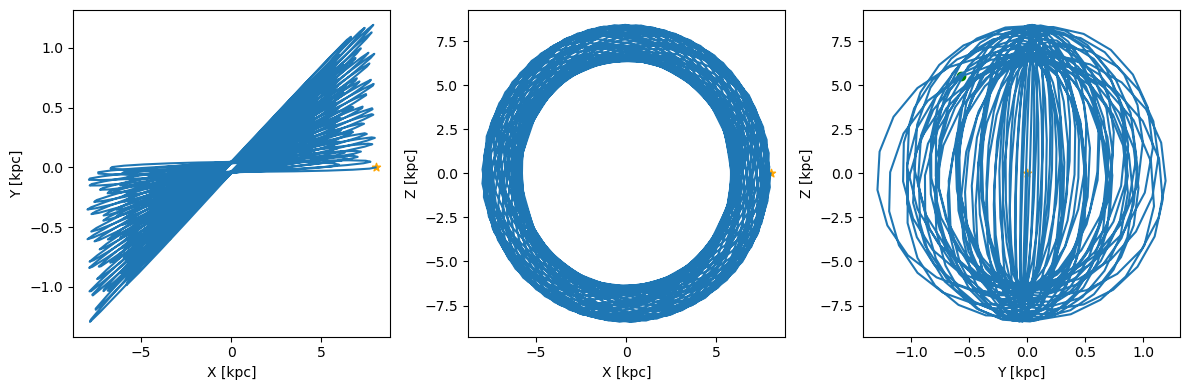

In [176]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [ ]:
def stellar_energy(N,M,R,v,its_sum):
    b=np.random.uniform(100*R, 1e-4,N) #is this a good choice? should i use logscale??? is 100r-1pc good?
    print(b)
    E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)


In [161]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [162]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]
SD=[]
SD_t=[]

In [ ]:
color_index=0
SD_count=0
while time_i < simulation_time:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=100, accuracy=1e-16,verbose=False)

    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=0.0001)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    

    Ei=binding_energy(mc_mass,mc_rvir)
    delEbyE=abs(delE/Ei)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=total_energy(Ei)+(1-get_fej(delEbyE))*delE+get_fub(delEbyE)*total_energy(Ei)

    

    Ef_array.append(Ef)
    Ei_array.append(total_energy(Ei))
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*total_energy(Ei))
    
    mc_mass=mc_mass-mass_loss
    mc_rvir=(kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef if N_encounter_with_star > 1 else mc_rvir     #mass and radius update
    

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)
    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)

    if mc_rvir==0:
        print('dead',pnum)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0)
        time_left=simulation_time-time_i
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=time_left, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
        flag='dead'
        
        


        break
    
    
    

    
    
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=True)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
        #if mcp_xv.size>0: mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0) 
    if mcp_xv.size>0:mcp_xv_temp+=mc_orbit_center[-1]
    else: mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
 
    if pnum>0:
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1 

    mc_center = mc_orbit_center[-1]

    time_i += tupd
    #SVT
    if mcp_xv.size>1000 and SD_count%10==0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)

        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i)

    print(time_i)
    SD_count+=1

color=np.array(color[1:])


0.01
0.02
dead 531


/suphys/aani0116/Work/minicluster_clean/my_modules/generate_particles.py:31: RuntimeWarning: invalid value encountered in scalar divide
  v_ideal=np.sqrt(agama.G*M/R)


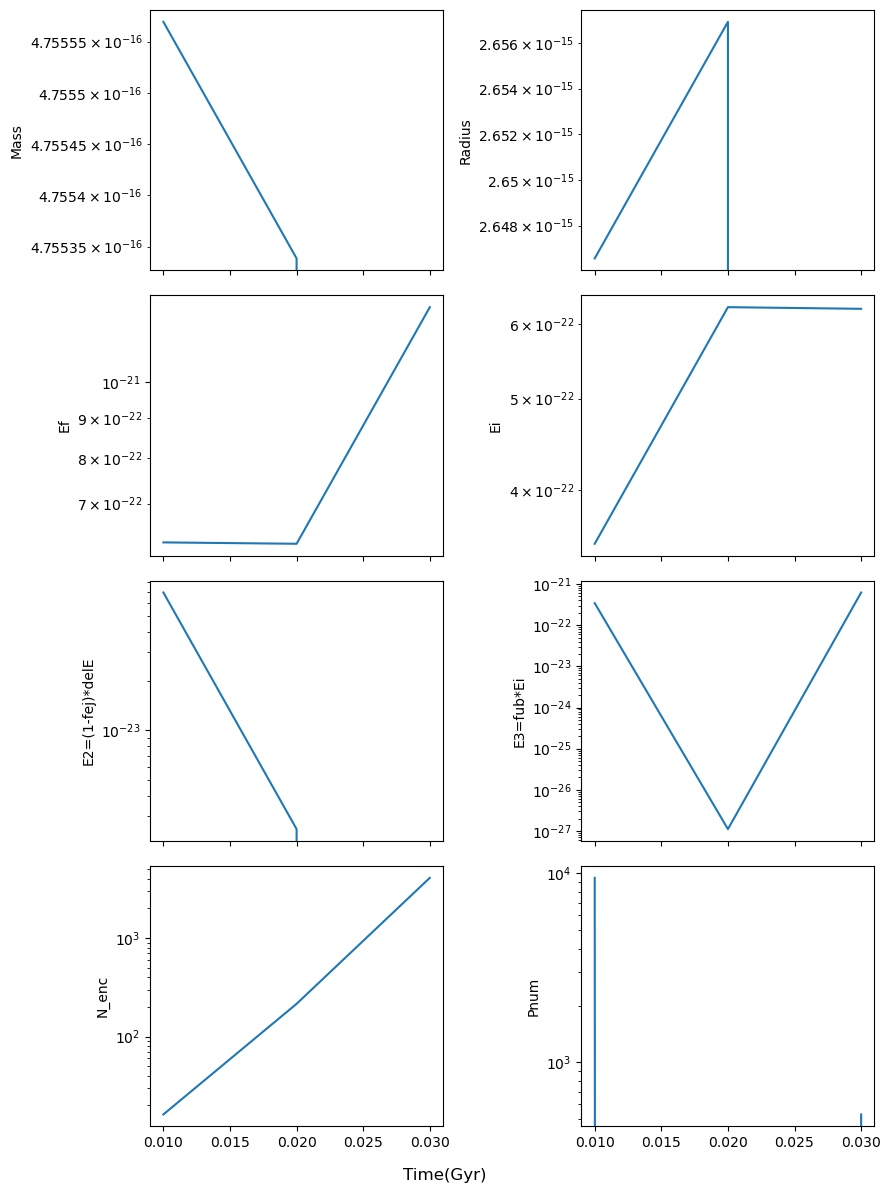

In [164]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

In [ ]:
SD=np.array(SD)
SD_t=np.array(SD_t)

In [ ]:
SD_t

In [ ]:
SD[:,0]

In [ ]:
plt.plot(SD_t,SD[:,0],marker='.')
plt.plot(SD_t,SD[:,1])
plt.plot(SD_t,SD[:,2])
plt.yscale('log')

In [143]:
mcp_xv

array([[  -4.93696806,   -0.81168227,    3.59240991, -113.80286555,
         -20.33064984, -223.05632269],
       [  -4.93696808,   -0.81168226,    3.59240991, -113.80286699,
         -20.33064967, -223.05632317],
       [  -4.93696807,   -0.81168225,    3.59240991, -113.80286707,
         -20.33065014, -223.05632214],
       ...,
       [  -4.93696805,   -0.81168227,    3.59240992, -113.80286674,
         -20.33064892, -223.05632276],
       [  -4.93696806,   -0.81168226,    3.59240993, -113.8028663 ,
         -20.33064944, -223.05632168],
       [  -4.93696808,   -0.81168226,    3.59240991, -113.80286616,
         -20.33065001, -223.05632172]], shape=(4864, 6))

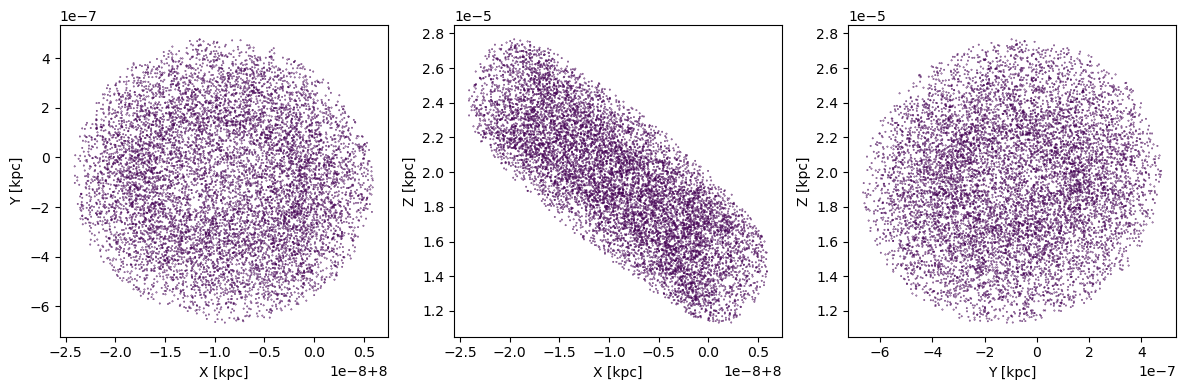

In [165]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [166]:
np.savez(f"sigma_data/mc{i}_{flag}.npy",
         mcp_xv=mcp_xv,
         mcp_mass=mcp_mass,
         mc_mass=mc.mass,
         mc_radius=mc.radius,
         color=color,
         mc_start=mc_center_start,
         mc_end=final_pos,
         t_array=t_array,
         orbit_array=orbit_array,
         SD=SD,
         SD_t=SD_t,
         SD_r=SD_r
         )

array([0., 0., 0., ..., 0., 0., 0.], shape=(9469,))